> simulando como seria ao receber uma extração simplificada do comércio exterior brasileiro com parceiros estratégicos (china & eua) em bilhões de dólares.

In [ ]:
import pandas as pd

# simulando dados inspirados no comex stat
dados_comercio = {
    "Ano": [2024, 2024, 2025, 2025],

    "Parceiro": ["China", "EUA", "China", "EUA"],
    "Exportacoes_US_Bi": [94.4, 40.3, 98.1, 41.5],
    "Importacoes_US_Bi": [63.6, 40.6, 61.2, 43.0],
}

df = pd.DataFrame(dados_comercio)

In [ ]:
#saldo da balança comercial (exports - imports)
df["Saldo_Comercial"] = df["Exportacoes_US_Bi"] - df["Importacoes_US_Bi"]

In [ ]:
#classificando o resultado em superávit ou déficit
def classificar_balanca(saldo):
    if saldo > 0:
        return "Superávit"
    elif saldo < 0:
        return "Déficit"
    else:
        return "Equilíbrio"


df["Status"] = df["Saldo_Comercial"].apply(classificar_balanca)

In [ ]:
#resultado final - exibir
print(df)

    Ano Parceiro  Exportacoes_US_Bi  Importacoes_US_Bi
0  2024    China               94.4               63.6
1  2024      EUA               40.3               40.6
2  2025    China               98.1               61.2
3  2025      EUA               41.5               43.0


usando o método `df.groupby("Parceiro")["Saldo_Comercial"].sum()` ao final do código para descobrir qual foi o saldo acumulado de cada país somando os dois anos.

In [ ]:
# clcnd o saldo acumulado por parceiro comercial
saldo_acumulado = df.groupby("Parceiro")["Saldo_Comercial"].sum().reset_index()

# resultado formatado
display(saldo_acumulado)

,Parceiro,Saldo_Comercial
0,China,67.7
1,EUA,-1.8


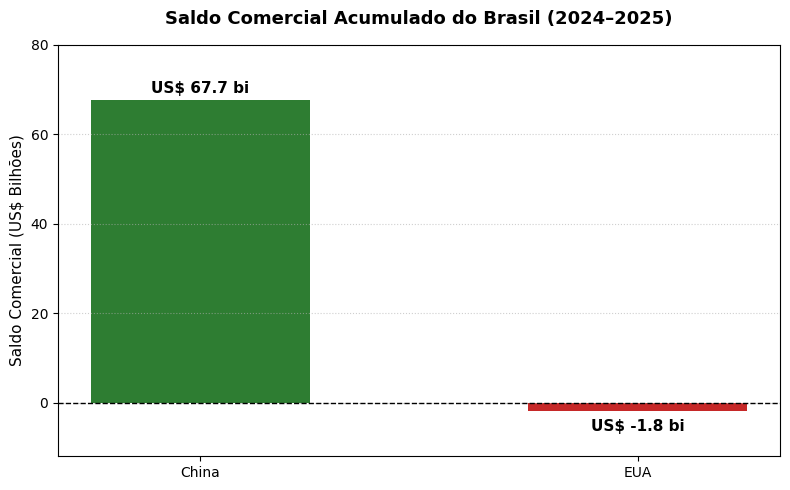

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

try:
    saldo_acumulado
except NameError:
    dados_comercio = {
        "Ano": [2024, 2024, 2025, 2025],
        "Parceiro": ["China", "EUA", "China", "EUA"],
        "Exportacoes_US_Bi": [94.4, 40.3, 98.1, 41.5],
        "Importacoes_US_Bi": [63.6, 40.6, 61.2, 43.0],
    }
    df = pd.DataFrame(dados_comercio)
    df["Saldo_Comercial"] = df["Exportacoes_US_Bi"] - df["Importacoes_US_Bi"]
    saldo_acumulado = df.groupby("Parceiro")["Saldo_Comercial"].sum().reset_index()

# 1. verde para superávit, vermelho para déficit
cores = [
    "#2e7d32" if valor > 0 else "#c62828"
    for valor in saldo_acumulado["Saldo_Comercial"]
]

# 2. criando a figura e as barras
plt.figure(figsize=(8, 5))
barras = plt.bar(
    saldo_acumulado["Parceiro"],
    saldo_acumulado["Saldo_Comercial"],
    color=cores,
    width=0.5,
)

# 3. linha de referência no zero (equilíbrio comercial)
plt.axhline(0, color="black", linewidth=1, linestyle="--")

# 4. add os valores exatos em cima/baixo de cada barra
for barra in barras:
    altura = barra.get_height()
    deslocamento = 1.5 if altura > 0 else -4.5
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        altura + deslocamento,
        f"US$ {altura:.1f} bi",
        ha="center",
        fontweight="bold",
        fontsize=11,
    )

# 5. títulos, rótulos e ajustes de margem
plt.title(
    "Saldo Comercial Acumulado do Brasil (2024–2025)",
    fontsize=13,
    fontweight="bold",
    pad=15,
)
plt.ylabel("Saldo Comercial (US$ Bilhões)", fontsize=11)
plt.ylim(-12, 80)
plt.grid(axis="y", linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()